# Module 6 Lab 3: Textbook Appendix C – Retrieve and Search

### Create the Database and Customers Table

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("lab3.db")

con.execute("DROP TABLE IF EXISTS customers")

con.execute("""
    CREATE TABLE customers (
        id INTEGER PRIMARY KEY,
        name TEXT,
        city TEXT,
        age INTEGER
    )
""")

con.commit()

print("Customers table created successfully.")

Customers table created successfully.


### Insert Customer Records

In [2]:
con.execute("INSERT INTO customers VALUES (1, 'Anna Reed', 'Los Angeles', 25)")
con.execute("INSERT INTO customers VALUES (2, 'Mark Hill', 'Santa Monica', 32)")
con.execute("INSERT INTO customers VALUES (3, 'Lisa Brown', 'Culver City', 28)")
con.execute("INSERT INTO customers VALUES (4, 'David Stone', 'Torrance', 41)")
con.execute("INSERT INTO customers VALUES (5, 'Emma Green', 'Venice', 23)")
con.execute("INSERT INTO customers VALUES (6, 'John Miller', 'Inglewood', 36)")
con.execute("INSERT INTO customers VALUES (7, 'Sarah White', 'Pasadena', 30)")
con.execute("INSERT INTO customers VALUES (8, 'Peter Clark', 'Long Beach', 45)")

con.commit()

print("8 fictional customer records inserted successfully.")

8 fictional customer records inserted successfully.


### Filter Customers Using WHERE


In [3]:
older_customers = pd.read_sql("""
    SELECT *
    FROM customers
    WHERE age > 30
""", con)

display(older_customers)

,id,name,city,age
0,2,Mark Hill,Santa Monica,32
1,4,David Stone,Torrance,41
2,6,John Miller,Inglewood,36
3,8,Peter Clark,Long Beach,45


### Sort Customers Using ORDER BY

In [4]:
sorted_customers = pd.read_sql("""
    SELECT *
    FROM customers
    ORDER BY age DESC
""", con)

display(sorted_customers)

,id,name,city,age
0,8,Peter Clark,Long Beach,45
1,4,David Stone,Torrance,41
2,6,John Miller,Inglewood,36
3,2,Mark Hill,Santa Monica,32
4,7,Sarah White,Pasadena,30
5,3,Lisa Brown,Culver City,28
6,1,Anna Reed,Los Angeles,25
7,5,Emma Green,Venice,23


### Search Customer Names Using LIKE

In [5]:
matching_customers = pd.read_sql("""
    SELECT *
    FROM customers
    WHERE name LIKE '%an%'
""", con)

display(matching_customers)

,id,name,city,age
0,1,Anna Reed,Los Angeles,25


### Create a Chart from an SQL Query

In [6]:
city_counts = pd.read_sql("""
    SELECT city, COUNT(*) AS customer_count
    FROM customers
    GROUP BY city
    ORDER BY city
""", con)

display(city_counts)

,city,customer_count
0,Culver City,1
1,Inglewood,1
2,Long Beach,1
3,Los Angeles,1
4,Pasadena,1
5,Santa Monica,1
6,Torrance,1
7,Venice,1


# Analyst's Statement

### Our dataset has only eight customers, with one customer in each city. A chart showing the number of customers by city would not show any differences. Comparing ages by city would also represent only one person per city. An age distribution chart would be more useful for showing differences within this small dataset.

In [7]:
age_distribution = pd.read_sql("""
    SELECT
        CASE
            WHEN age BETWEEN 20 AND 29 THEN '20-29'
            WHEN age BETWEEN 30 AND 39 THEN '30-39'
            WHEN age BETWEEN 40 AND 49 THEN '40-49'
        END AS age_group,
        COUNT(*) AS customer_count
    FROM customers
    GROUP BY age_group
    ORDER BY age_group
""", con)

display(age_distribution)

,age_group,customer_count
0,20-29,3
1,30-39,3
2,40-49,2


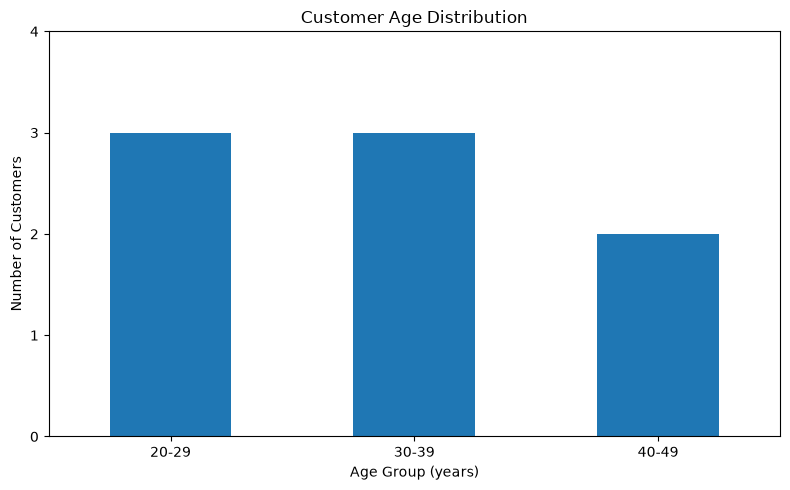

In [8]:
age_distribution.plot(
    kind="bar",
    x="age_group",
    y="customer_count",
    legend=False,
    figsize=(8, 5)
)

plt.title("Customer Age Distribution")
plt.xlabel("Age Group (years)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.yticks(range(0, 5))
plt.tight_layout()
plt.show()

### Customer Data Ethics Note

This lab uses fictional customer data. Grouping customers by age helps show patterns without revealing individual information.